In [3]:
import nibabel as nib
import matplotlib.pyplot as plt
from ipywidgets import IntSlider, interactive, VBox
from IPython.display import display, clear_output
import os
import numpy as np
from concurrent.futures import ThreadPoolExecutor, as_completed
import os
import numpy as np


def list_nifti_files_no_ex(directory):
    if not os.path.exists(directory):
        print(f"Directory {directory} does not exist.")
        return []
    nifti_files = []
    for root, _, files in os.walk(directory):        
        for file in files:
            if file.endswith(('.nii', '.nii.gz')):
                nifti_files.append(os.path.join(root, file))
    return nifti_files

def load_patient_files(patient_id):
    patient_path = os.path.join(test_folder, patient_id)
    nii_files = list_nifti_files_no_ex(patient_path)
    if not nii_files:
        print(f"No .nii.gz files found for patient {patient_id} in {patient_path}")
        return None
    data = []
    for f in nii_files:
        nifti_data = nib.load(f).get_fdata()
        data.append(nifti_data)
    return np.stack(data, axis=0)  # Stack all images for a patient

test_folder = "/home/bule/berner_daten_analyse/data/nifti_pascal_selection/test"

# 3d render

with ITK -> download all files and inspect

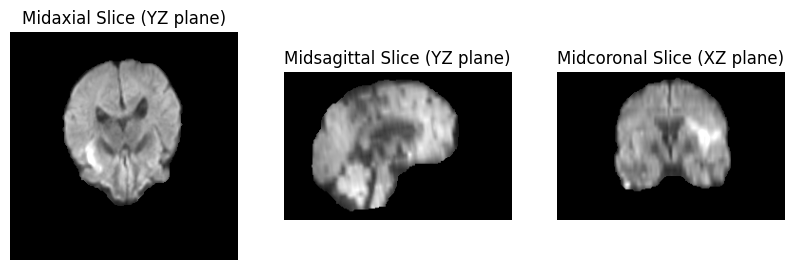

In [12]:
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt

# Load NIfTI file
nifti_path = "/home/bule/berner_daten_analyse/data/nifti_third_try/processed/76813/norm_bet_dir/dwi_bet_normalized.nii.gz"
nifti_img = nib.load(nifti_path)

# Get image data as a NumPy array
img_data = nifti_img.get_fdata()

# Get the middle index for each axis
mid_axial = img_data.shape[2] // 2  # 

mid_sagittal = img_data.shape[0] // 2  # Midpoint along left-right
mid_coronal = img_data.shape[1] // 2   # Midpoint along front-back

# Extract slices
axial_slice= img_data[:, :, mid_axial]  # Midaxial (XY plane)
sagittal_slice = img_data[mid_sagittal, :, :]  # Midsagittal (YZ plane)
coronal_slice = img_data[:, mid_coronal, :]    # Midcoronal (XZ plane)

# Plot the slices
fig, axes = plt.subplots(1, 3, figsize=(10, 5))

# Display Midaxial Slice
axes[0].imshow(np.rot90(axial_slice,3), cmap="gray")
axes[0].set_title("Midaxial Slice (YZ plane)")
axes[0].axis("off")

# Display Midsagittal Slice
axes[1].imshow(np.rot90(sagittal_slice), cmap="gray", origin="upper")
axes[1].set_title("Midsagittal Slice (YZ plane)")
axes[1].axis("off")

# Display Midcoronal Slice
axes[2].imshow(np.rot90(coronal_slice), cmap="gray", origin="upper")
axes[2].set_title("Midcoronal Slice (XZ plane)")
axes[2].axis("off")

plt.show()



- generate tensor from all the processed fiels

In [ ]:
# patient_ids = [d for d in os.listdir(test_folder) if os.path.isdir(os.path.join(test_folder, d))]
# patient_ids=sorted(patient_ids, key=lambda x: int(x))
# patient_ids

# all_patients_data = []

# for patient_id in patient_ids:
#     print(f"Loading data for patient {patient_id}")
    
#     # if int(patient_id) >= 11250836:
#     #     break
#     patient_data = load_patient_files(patient_id)
#     if patient_data is not None:
#         all_patients_data.append(patient_data)

# try:
#     combined_tensor = np.stack(all_patients_data, axis=0)
#     print(f"Combined tensor shape: {combined_tensor.shape}")
# except ValueError as e:
#     print(f"Error combining tensors: {e}")

In [ ]:

# batch_size = 10
# output_folder = "/home/bule/berner_daten_analyse/data/tmp"  # Replace with your desired save folder
# os.makedirs(output_folder, exist_ok=True)

# patient_ids = [d for d in os.listdir(test_folder) if os.path.isdir(os.path.join(test_folder, d))]
# patient_ids=sorted(patient_ids, key=lambda x: int(x))

# all_batches = []
# batch_data = []
# batch_index = 0

# for i, patient_id in enumerate(patient_ids):
    
#     if int(patient_id) >= 11300299:
#         break
#     print(f"Loading data for patient {patient_id}")
    
#     patient_data = load_patient_files(patient_id)  
#     if patient_data is not None:
#         batch_data.append(patient_data)
    
#     # When batch size is reached or it's the last patient, save the batch
#     if len(batch_data) == batch_size or i == len(patient_ids) - 1:
#         try:
#             batch_tensor = np.stack(batch_data, axis=0)
#             batch_file = os.path.join(output_folder, f"batch_{batch_index}.npy")
#             np.save(batch_file, batch_tensor)
#             print(f"Saved batch {batch_index} to {batch_file}, shape: {batch_tensor.shape}")
#             all_batches.append(batch_file)
#             batch_data = []
#             batch_index += 1
#         except ValueError as e:
#             print(f"Error combining batch tensors: {e}")



In [ ]:
# batchlist=[os.path.join("/home/bule/berner_daten_analyse/data/tmp",batch) for batch in os.listdir("/home/bule/berner_daten_analyse/data/tmp") if batch.endswith(".npy") and batch.startswith("batch")]
# batchlist=sorted(batchlist, key=lambda x: int(x.split("_")[-1].split(".")[0]))
# batchlist

In [ ]:
# output_file = "/home/bule/berner_daten_analyse/data/tmp/final_combined_tensor.npy"


# batch_shapes = [np.load(batch).shape for batch in batchlist]
# total_patients = sum(batch_shape[0] for batch_shape in batch_shapes)

# if not os.path.exists(output_file):
#     batch_shapes = [np.load(batch).shape for batch in batchlist]
#     total_patients = sum(batch_shape[0] for batch_shape in batch_shapes)
#     tensor_shape = batch_shapes[0][1:]

#     combined_tensor = np.memmap(output_file, dtype='float32', mode='w+', shape=(total_patients, *tensor_shape))

#     start_idx = 0
#     for batch in batchlist:
#         batch_data = np.load(batch)
#         end_idx = start_idx + batch_data.shape[0]
#         combined_tensor[start_idx:end_idx] = batch_data
#         start_idx = end_idx
#         print(f"Processed batch {batch}, current shape: {combined_tensor[:end_idx].shape}")

#     combined_tensor.flush()
#     print(f"Final combined tensor saved to {output_file}, shape: {combined_tensor.shape}")
# else:
#     # Load the memory-mapped tensor
#     print("Loading existing combined tensor...")
#     combined_tensor = np.memmap(output_file, dtype='float32', mode='r', shape=(total_patients, *tensor_shape))


# print(f"Loaded tensor shape: {combined_tensor.shape}")


In [9]:
tensor_shape = (14, 240, 240, 155)
combined_tensor = np.memmap(output_file, dtype='float32', mode='r', shape=(130, *tensor_shape))


- display them 

In [ ]:

#get titles 
modnames=[os.path.split(path)[1][:-7]for path in list_nifti_files_no_ex(os.path.join(test_folder, str(76813)))]

def view_patient_slices(patient_idx, slice_idx):
    clear_output(wait=True)  # Clear previous output to avoid duplicate plots
    num_volumes = combined_tensor.shape[1]
    rows, cols = 2, 7  
    fig, axes = plt.subplots(rows, cols, figsize=(30, 10))
    axes = axes.flatten()  

    for vol in range(num_volumes):
        ax = axes[vol]
        ax.imshow(combined_tensor[patient_idx, vol, :, :, slice_idx], cmap="gray", origin="lower")
        ax.set_title(modnames[vol])
        ax.axis("off")
    
    for unused_ax in axes[num_volumes:]:
        unused_ax.axis("off")
    
    plt.tight_layout()
    plt.show()

patient_slider = IntSlider(min=0, max=combined_tensor.shape[0] - 1, step=1, value=0, description="Patient")
slice_slider = IntSlider(min=0, max=combined_tensor.shape[4] - 1, step=1, value=70, description="Slice")

interactive_view = interactive(view_patient_slices, patient_idx=patient_slider, slice_idx=slice_slider)
display(VBox([interactive_view]))

